<a href="https://colab.research.google.com/github/SantiDrelewicz/prode/blob/main/Prode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚽ Prode Predictivo: Premier League
Este notebook descarga datos históricos, realiza análisis exploratorio (EDA), calcula un sistema de ranking Elo y entrena 3 modelos predictivos basados en XGBoost. Finalmente, utiliza una distribución de Poisson para simular resultados exactos de partidos.

In [1]:
!pip install -q understatapi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 537.7/537.7 kB 10.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.4/159.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.1/153.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.1/138.1 kB 5.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.
blobfile 3.3.0 requires urllib3>=2,

In [2]:
# ==========================================
# 1. IMPORTACIÓN Y CREDENCIALES
# ==========================================
import os
import time
from typing import Any, Literal
import warnings
warnings.filterwarnings('ignore')

# API de Datos
from understatapi import UnderstatClient

# Manipulación de datos y visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelado y estadística
from scipy.stats import poisson
import xgboost as xgb
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

## 2. Descarga y Carga de Datos

In [3]:
# ==========================================
# 2. DESCARGA Y LIMPIEZA DE DATASETS (UNDERSTAT)
# ==========================================
print("Descargando dataset histórico directo desde Understat (2014 - Actualidad) para todas las ligas...")

seasons = [str(year) for year in range(2014, 2026)]

leagues = ['EPL', 'La_Liga', 'Bundesliga', 'Serie_A', 'Ligue_1', 'RFPL']

all_matches = []

with UnderstatClient() as understat:
    for league in leagues:
        print(f"--- Descargando liga: {league} ---")
        for season in seasons:
            try:
                data = understat.league(league=league).get_match_data(season=season)

                for match in data:
                    # Solo procesamos los partidos que ya se jugaron ('isResult' == True)
                    if match['isResult']:
                        date = match['datetime']

                        # Fila para el equipo LOCAL
                        all_matches.append({
                            'league': league,
                            'date': date,
                            'season': season,
                            'team': match['h']['title'],
                            'opponent': match['a']['title'],
                            'venue': 'h',
                            'gf': int(match['goals']['h']),
                            'ga': int(match['goals']['a']),
                            'xg': float(match['xG']['h']),
                            'xga': float(match['xG']['a'])
                        })

                        # Fila para el equipo VISITANTE
                        all_matches.append({
                            'league': league,
                            'date': date,
                            'season': season,
                            'team': match['a']['title'],
                            'opponent': match['h']['title'],
                            'venue': 'a',
                            'gf': int(match['goals']['a']),
                            'ga': int(match['goals']['h']),
                            'xg': float(match['xG']['a']),
                            'xga': float(match['xG']['h'])
                        })
            except Exception as e:
                print(f"No se pudo descargar {league} - temporada {season}: {e}")

            time.sleep(1)

df = pd.DataFrame(all_matches)

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(by=['league', 'date', 'team']).reset_index(drop=True)



Descargando dataset histórico directo desde Understat (2014 - Actualidad) para todas las ligas...
--- Descargando liga: EPL ---
--- Descargando liga: La_Liga ---
--- Descargando liga: Bundesliga ---
--- Descargando liga: Serie_A ---
--- Descargando liga: Ligue_1 ---
--- Descargando liga: RFPL ---


In [4]:
df

,league,date,season,team,opponent,venue,gf,ga,xg,xga
0,Bundesliga,2014-08-22 19:30:00,2014,Bayern Munich,Wolfsburg,h,2,1,2.570120,1.198420
1,Bundesliga,2014-08-22 19:30:00,2014,Wolfsburg,Bayern Munich,a,1,2,1.198420,2.570120
2,Bundesliga,2014-08-23 14:30:00,2014,Augsburg,Hoffenheim,a,0,2,0.280777,1.528730
3,Bundesliga,2014-08-23 14:30:00,2014,Eintracht Frankfurt,Freiburg,h,1,0,1.753310,1.380840
4,Bundesliga,2014-08-23 14:30:00,2014,FC Cologne,Hamburger SV,h,0,0,0.522276,0.913337
...,...,...,...,...,...,...,...,...,...,...
48933,Serie_A,2026-05-24 18:45:00,2025,Juventus,Torino,a,2,2,2.534270,0.950066
48934,Serie_A,2026-05-24 18:45:00,2025,Lecce,Genoa,h,1,0,2.213870,0.782331
48935,Serie_A,2026-05-24 18:45:00,2025,Roma,Verona,a,2,0,3.555060,0.597669
48936,Serie_A,2026-05-24 18:45:00,2025,Torino,Juventus,h,2,2,0.950066,2.534270


In [5]:
df.to_parquet("football_dataset.parquet", index=False)

In [6]:
df = pd.read_parquet("football_dataset.parquet")
df

,league,date,season,team,opponent,venue,gf,ga,xg,xga
0,Bundesliga,2014-08-22 19:30:00,2014,Bayern Munich,Wolfsburg,h,2,1,2.570120,1.198420
1,Bundesliga,2014-08-22 19:30:00,2014,Wolfsburg,Bayern Munich,a,1,2,1.198420,2.570120
2,Bundesliga,2014-08-23 14:30:00,2014,Augsburg,Hoffenheim,a,0,2,0.280777,1.528730
3,Bundesliga,2014-08-23 14:30:00,2014,Eintracht Frankfurt,Freiburg,h,1,0,1.753310,1.380840
4,Bundesliga,2014-08-23 14:30:00,2014,FC Cologne,Hamburger SV,h,0,0,0.522276,0.913337
...,...,...,...,...,...,...,...,...,...,...
48933,Serie_A,2026-05-24 18:45:00,2025,Juventus,Torino,a,2,2,2.534270,0.950066
48934,Serie_A,2026-05-24 18:45:00,2025,Lecce,Genoa,h,1,0,2.213870,0.782331
48935,Serie_A,2026-05-24 18:45:00,2025,Roma,Verona,a,2,0,3.555060,0.597669
48936,Serie_A,2026-05-24 18:45:00,2025,Torino,Juventus,h,2,2,0.950066,2.534270


In [14]:
import numpy as np

df_analysis = df.copy()

df_analysis['match_pair'] = np.where(df_analysis['team'] < df_analysis['opponent'],
                                     df_analysis['team'] + '-' + df_analysis['opponent'],
                                     df_analysis['opponent'] + '-' + df_analysis['team'])

df_analysis = df_analysis.sort_values(by=['league', 'season', 'date']).reset_index(drop=True)

df_analysis['match_id'] = df_analysis.groupby(['league', 'season', 'date', 'match_pair']).ngroup() + 1
df_analysis = df_analysis.drop(columns=['match_pair'])
df_analysis = df_analysis[df_analysis['venue'] == 'h'].copy()
df_analysis = df_analysis.drop(columns=['venue', 'date'])
df_analysis = df_analysis.reset_index(drop=True)

df_analysis['eff'] = df_analysis['gf'] - df_analysis['xg']   #Efectividad
df_analysis['eff_opp'] = df_analysis['ga'] - df_analysis['xga']  #Efectividad Oponente
df_analysis['xg_diff'] = df_analysis['xg'] - df_analysis['xga']     #Diferencia de ocasiones generadas
df_analysis['goal_diff'] = df_analysis['gf'] - df_analysis['ga']    #Diferencia de goles marcados



# Nos quedamos con las columnas deseadas en el nuevo DataFrame0
df_analysis = df_analysis[['match_id', 'league', 'season', 'team', 'opponent', 'gf', 'ga', 'xg','xga', 'eff', 'eff_opp', 'xg_diff','goal_diff']]

In [15]:
df_analysis

,match_id,league,season,team,opponent,gf,ga,xg,xga,eff,eff_opp,xg_diff,goal_diff
0,1,Bundesliga,2014,Bayern Munich,Wolfsburg,2,1,2.570120,1.198420,-0.570120,-0.198420,1.371700,1
1,3,Bundesliga,2014,Eintracht Frankfurt,Freiburg,1,0,1.753310,1.380840,-0.753310,-1.380840,0.372470,1
2,4,Bundesliga,2014,FC Cologne,Hamburger SV,0,0,0.522276,0.913337,-0.522276,-0.913337,-0.391061,0
3,5,Bundesliga,2014,Hannover 96,Schalke 04,2,1,1.179790,0.956665,0.820210,0.043335,0.223125,1
4,6,Bundesliga,2014,Hertha Berlin,Werder Bremen,2,2,1.755850,1.194530,0.244150,0.805470,0.561320,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24464,24465,Serie_A,2025,AC Milan,Cagliari,1,2,1.759530,3.436240,-0.759530,-1.436240,-1.676710,-1
24465,24466,Serie_A,2025,Cremonese,Como,1,4,0.977192,2.691100,0.022808,1.308900,-1.713908,-3
24466,24467,Serie_A,2025,Lecce,Genoa,1,0,2.213870,0.782331,-1.213870,-0.782331,1.431539,1
24467,24468,Serie_A,2025,Torino,Juventus,2,2,0.950066,2.534270,1.049934,-0.534270,-1.584204,0


In [16]:
df["season"].unique()


array(['2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021',
       '2022', '2023', '2024', '2025'], dtype=object)

## 3. Análisis Exploratorio de Datos
Análisis de variables clave como la diferencia de goles esperados (xG), el impacto de la localía y la eficiencia goleadora.

In [17]:
df_analysis = df_analysis.dropna()
df_analysis = df_analysis.drop_duplicates()
df.shape[0]


48938

In [18]:

equipo_ejemplo = 'Bayern Munich'
temporada_objetivo = '2023'

df_filtrado = df_analysis[(df_analysis['team'] == equipo_ejemplo) & (df_analysis['season'] == temporada_objetivo)]

print(df_filtrado[['match_id', 'team', 'opponent']].head(1000))

      match_id           team                opponent
2771      2772  Bayern Munich                Augsburg
2781      2782  Bayern Munich        Bayer Leverkusen
2792      2793  Bayern Munich                  Bochum
2815      2816  Bayern Munich                Freiburg
2828      2829  Bayern Munich               Darmstadt
2846      2847  Bayern Munich           FC Heidenheim
2887      2888  Bayern Munich           VfB Stuttgart
2897      2898  Bayern Munich              Hoffenheim
2912      2913  Bayern Munich           Werder Bremen
2914      2915  Bayern Munich            Union Berlin
2925      2928  Bayern Munich     Borussia M.Gladbach
2957      2958  Bayern Munich  RasenBallsport Leipzig
2972      2973  Bayern Munich                Mainz 05
2993      2994  Bayern Munich       Borussia Dortmund
3007      3008  Bayern Munich              FC Cologne
3026      3027  Bayern Munich     Eintracht Frankfurt
3049      3050  Bayern Munich               Wolfsburg


In [19]:
import pandas as pd

df_analysis['team_1'] = df_analysis[['team', 'opponent']].min(axis=1)
df_analysis['team_2'] = df_analysis[['team', 'opponent']].max(axis=1)

conteo_pares = df_analysis.groupby(['league', 'season', 'team_1', 'team_2']).size().reset_index(name='total_partidos')

maximo_absoluto = conteo_pares['total_partidos'].max()

print("Hay máximo  " + str(maximo_absoluto) +  "  coincidencias de enfrentamientos por temporada.")

Hay máximo  2  coincidencias de enfrentamientos por temporada.


In [20]:
partidos_por_torneo = df.groupby(['league', 'season']).size().reset_index(name='total_registros')



# 2. Calcular las métricas generales (promedio, máximo y mínimo) de partidos por temporada para cada liga
resumen_ligas = partidos_por_torneo.groupby('league')['total_registros'].agg(
    promedio_por_temporada='mean',
    maximo_temporada='max',
    minimo_temporada='min',
    total_temporadas_registradas='count'
).reset_index()

# Redondear el promedio para que quede prolijo
resumen_ligas['promedio_por_temporada'] = resumen_ligas['promedio_por_temporada'].round(1)

print("--- Resumen de partidos por temporada para cada liga ---")
print(resumen_ligas.to_string(index=False))

--- Resumen de partidos por temporada para cada liga ---
    league  promedio_por_temporada  maximo_temporada  minimo_temporada  total_temporadas_registradas
Bundesliga                   612.0               612               612                            12
       EPL                   760.0               760               760                            12
   La_Liga                   760.0               760               760                            12
   Ligue_1                   706.2               760               558                            12
      RFPL                   480.0               480               480                            12
   Serie_A                   760.0               760               760                            12


In [21]:
# Contar la cantidad de equipos únicos por liga y temporada
equipos_por_temporada = df.groupby(['league', 'season'])['team'].nunique().reset_index(name='total_equipos')

print("--- Cantidad de equipos por liga y temporada ---")
print(equipos_por_temporada.to_string(index=False))

--- Cantidad de equipos por liga y temporada ---
    league season  total_equipos
Bundesliga   2014             18
Bundesliga   2015             18
Bundesliga   2016             18
Bundesliga   2017             18
Bundesliga   2018             18
Bundesliga   2019             18
Bundesliga   2020             18
Bundesliga   2021             18
Bundesliga   2022             18
Bundesliga   2023             18
Bundesliga   2024             18
Bundesliga   2025             18
       EPL   2014             20
       EPL   2015             20
       EPL   2016             20
       EPL   2017             20
       EPL   2018             20
       EPL   2019             20
       EPL   2020             20
       EPL   2021             20
       EPL   2022             20
       EPL   2023             20
       EPL   2024             20
       EPL   2025             20
   La_Liga   2014             20
   La_Liga   2015             20
   La_Liga   2016             20
   La_Liga   2017          

In [22]:
partidos_por_torneo = df_analysis.groupby(['league', 'season']).size().reset_index(name='total_registros')

resumen_ligas = partidos_por_torneo.groupby('league')['total_registros'].agg(
    promedio_por_temporada='mean',
    maximo_temporada='max',
    minimo_temporada='min',
    total_temporadas_registradas='count'
).reset_index()

resumen_ligas['promedio_por_temporada'] = resumen_ligas['promedio_por_temporada'].round(1)

print("--- Resumen de partidos por temporada para cada liga ---")
print(resumen_ligas.to_string(index=False))

--- Resumen de partidos por temporada para cada liga ---
    league  promedio_por_temporada  maximo_temporada  minimo_temporada  total_temporadas_registradas
Bundesliga                   306.0               306               306                            12
       EPL                   380.0               380               380                            12
   La_Liga                   380.0               380               380                            12
   Ligue_1                   353.1               380               279                            12
      RFPL                   240.0               240               240                            12
   Serie_A                   380.0               380               380                            12


In [23]:
conteo_temporadas = df_analysis.groupby(['league', 'season']).size().reset_index(name='total_partidos')

ligue_1_temp = conteo_temporadas[conteo_temporadas['league'] == 'Ligue_1']

temporada_rara = ligue_1_temp.sort_values(by='total_partidos').head(1)

print("--- Temporada anómala en Ligue_1 ---")
print(temporada_rara.to_string(index=False))

--- Temporada anómala en Ligue_1 ---
 league season  total_partidos
Ligue_1   2019             279


In [24]:
conteo_temporadas = df_analysis.groupby(['league', 'season']).size().reset_index(name='total_partidos')
temporada_rara = conteo_temporadas[(conteo_temporadas['league'] == 'Ligue_1') & (conteo_temporadas['total_partidos'] < 300)]['season'].values[0]

print(f"Temporada detectada automáticamente: {temporada_rara}\n")

df_ligue1_rara = df_analysis[(df_analysis['league'] == 'Ligue_1') & (df_analysis['season'] == temporada_rara)].copy()

conteo_por_equipo = df_ligue1_rara['team'].value_counts().reset_index()
conteo_por_equipo.columns = ['team', 'partidos_jugados']

print("--- Partidos jugados por cada equipo en esa temporada ---")
print(conteo_por_equipo.to_string(index=False))

Temporada detectada automáticamente: 2019

--- Partidos jugados por cada equipo en esa temporada ---
               team  partidos_jugados
             Angers                15
              Lille                15
               Nice                15
             Monaco                14
              Brest                14
          Marseille                14
        Montpellier                14
              Dijon                14
Paris Saint Germain                14
             Nantes                14
               Metz                14
             Amiens                14
             Rennes                14
              Reims                14
              Nimes                14
      Saint-Etienne                14
               Lyon                13
         Strasbourg                13
           Bordeaux                13
           Toulouse                13


Buscando online se suspendió la liga en abril por el covid y no se terminaron todos los partidos.

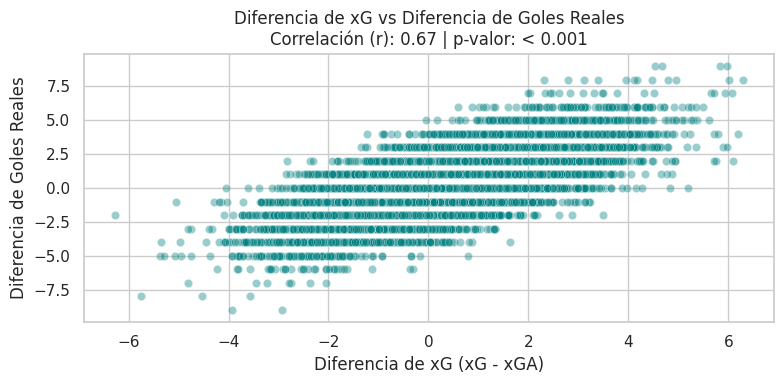

In [25]:


df_clean = df_analysis.dropna(subset=['xg_diff', 'goal_diff'])
r, p_value = pearsonr(df_clean['xg_diff'], df_clean['goal_diff'])

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df_analysis, x='xg_diff', y='goal_diff', alpha=0.4, color='teal')

p_text = f"< 0.001" if p_value < 0.001 else f"{p_value:.4f}"
stats_text = f"Correlación (r): {r:.2f} | p-valor: {p_text}"

plt.title(f'Diferencia de xG vs Diferencia de Goles Reales\n{stats_text}', fontsize=12)
plt.xlabel('Diferencia de xG (xG - xGA)')
plt.ylabel('Diferencia de Goles Reales')

plt.tight_layout()
plt.show()

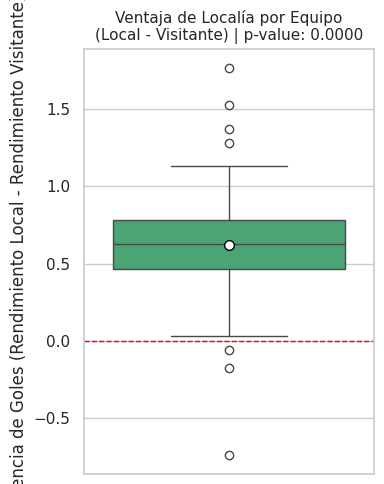

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_1samp


df_local = df_analysis.groupby('team')['goal_diff'].mean().reset_index()
df_local.columns = ['Equipo', 'Dif_Goles_Local']

df_visitante = df_analysis.groupby('opponent')['goal_diff'].apply(lambda x: (-x).mean()).reset_index()
df_visitante.columns = ['Equipo', 'Dif_Goles_Visita']

df_test = pd.merge(df_local, df_visitante, on='Equipo')
df_test['Ventaja_Localia'] = df_test['Dif_Goles_Local'] - df_test['Dif_Goles_Visita']


t_stat, p_value = ttest_1samp(df_test['Ventaja_Localia'].dropna(), 0)


plt.figure(figsize=(4, 5))

sns.boxplot(
    data=df_test,
    y='Ventaja_Localia',
    color='mediumseagreen',
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"7"}
)

plt.axhline(0, color='red', linestyle='--', linewidth=1)

plt.title(f'Ventaja de Localía por Equipo\n(Local - Visitante) | p-value: {p_value:.4f}', fontsize=11)
plt.ylabel('Diferencia de Goles (Rendimiento Local - Rendimiento Visitante)')

plt.xticks([])
plt.tight_layout()
plt.show()

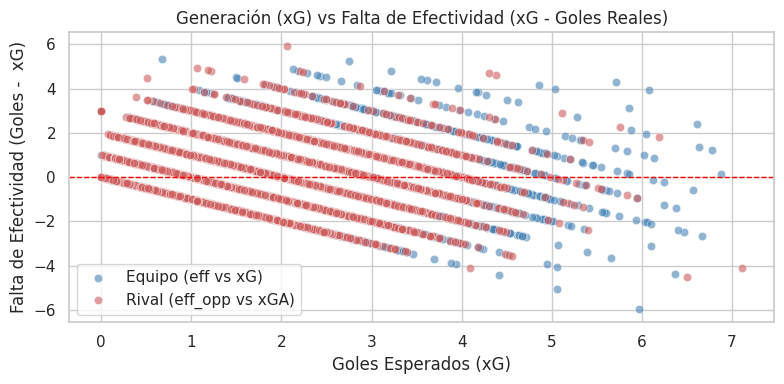

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.scatterplot(data=df_analysis, x='xg', y='eff', alpha=0.6, color='steelblue', label='Equipo (eff vs xG)')

sns.scatterplot(data=df_analysis, x='xga', y='eff_opp', alpha=0.6, color='indianred', label='Rival (eff_opp vs xGA)')

plt.axhline(0, color='red', linestyle='--', linewidth=1)

plt.title('Generación (xG) vs Falta de Efectividad (xG - Goles Reales)')
plt.xlabel('Goles Esperados (xG)')
plt.ylabel('Falta de Efectividad (Goles -  xG)')

plt.legend()

plt.tight_layout()
plt.show()

## 4. Feature Engineering y Sistema Elo
Cálculo del ranking Elo pre-partido y generación de promedios móviles (últimos 6 partidos) para capturar el estado de forma.

In [28]:
import pandas as pd
import numpy as np
import itertools

# ==============================================================================
# 1. FUNCIÓN MODULAR DEL MOTOR (ELO + PRODEGY + EFICIENCIA)
# ==============================================================================
def ejecutar_motor_ratings(df_partidos, cfg, modo_descubrimiento=False, partidos_para_aprender=8):
    elo_dict, xos_dict, xds_dict = {}, {}, {}
    eos_dict, eds_dict = {}, {}

    partidos_jugados, es_ascendido = {}, {}
    equipos_temp_anterior = set()

    temporada_actual = None
    es_primera_temporada = True

    resultados_produccion = []
    descubrimiento = {'elo': [], 'xos': [], 'xds': [], 'brier_error': [], 'xg_error': [], 'goles_error': []}

    def obtener_tasa(equipo, tasa_normal, tasa_alta):
        es_asc = es_ascendido.get(equipo, False)
        if modo_descubrimiento and es_asc and partidos_jugados.get(equipo, 0) < partidos_para_aprender + 2:
            return tasa_alta
        elif not modo_descubrimiento and partidos_jugados.get(equipo, 0) < 5:
            return tasa_alta
        return tasa_normal

    for _, row in df_partidos.iterrows():
        match_id, home, away, season = row['match_id'], row['team'], row['opponent'], row['season']
        gf, ga, xg, xga = row['gf'], row['ga'], row['xg'], row['xga']

        if temporada_actual is None:
            temporada_actual = season
        elif season != temporada_actual:
            for t in elo_dict: elo_dict[t] -= cfg['REG_ELO'] * (elo_dict[t] - cfg['ELO_DEFAULT'])
            for t in xos_dict: xos_dict[t] -= cfg['REG_XG'] * (xos_dict[t] - cfg['XOS_DEFAULT'])
            for t in xds_dict: xds_dict[t] -= cfg['REG_XG'] * (xds_dict[t] - cfg['XDS_DEFAULT'])
            for t in eos_dict: eos_dict[t] -= cfg['REG_EFF'] * (eos_dict[t] - cfg['EFF_DEFAULT'])
            for t in eds_dict: eds_dict[t] -= cfg['REG_EFF'] * (eds_dict[t] - cfg['EFF_DEFAULT'])

            if elo_dict:
                ajuste_elo = cfg['ELO_DEFAULT'] - np.mean(list(elo_dict.values()))
                ajuste_xos = cfg['XOS_DEFAULT'] - np.mean(list(xos_dict.values()))
                ajuste_xds = cfg['XDS_DEFAULT'] - np.mean(list(xds_dict.values()))
                ajuste_eos = cfg['EFF_DEFAULT'] - np.mean(list(eos_dict.values()))
                ajuste_eds = cfg['EFF_DEFAULT'] - np.mean(list(eds_dict.values()))

                for t in elo_dict:
                    elo_dict[t] += ajuste_elo
                    xos_dict[t] += ajuste_xos
                    xds_dict[t] += ajuste_xds
                    eos_dict[t] += ajuste_eos
                    eds_dict[t] += ajuste_eds

            equipos_temp_anterior = set(partidos_jugados.keys())
            partidos_jugados.clear()
            es_ascendido.clear()
            temporada_actual = season
            es_primera_temporada = False

        for t in [home, away]:
            if t not in elo_dict:
                elo_dict[t] = cfg['ELO_DEFAULT'] if es_primera_temporada else cfg['ELO_ASCENDIDO']
                xos_dict[t] = cfg['XOS_DEFAULT'] if es_primera_temporada else cfg['XOS_ASCENDIDO']
                xds_dict[t] = cfg['XDS_DEFAULT'] if es_primera_temporada else cfg['XDS_ASCENDIDO']
                eos_dict[t] = cfg['EFF_DEFAULT']
                eds_dict[t] = cfg['EFF_DEFAULT']
                partidos_jugados[t] = 0
                es_ascendido[t] = not es_primera_temporada
            elif t not in partidos_jugados:
                partidos_jugados[t] = 0
                if t not in equipos_temp_anterior:
                    elo_dict[t] = cfg['ELO_ASCENDIDO']
                    xos_dict[t] = cfg['XOS_ASCENDIDO']
                    xds_dict[t] = cfg['XDS_ASCENDIDO']
                    eos_dict[t] = cfg['EFF_DEFAULT']
                    eds_dict[t] = cfg['EFF_DEFAULT']
                    es_ascendido[t] = True
                else:
                    es_ascendido[t] = False

        elo_h, xos_h, xds_h = elo_dict[home], xos_dict[home], xds_dict[home]
        elo_a, xos_a, xds_a = elo_dict[away], xos_dict[away], xds_dict[away]
        eos_h, eds_h = eos_dict[home], eds_dict[home]
        eos_a, eds_a = eos_dict[away], eds_dict[away]

        if not modo_descubrimiento:
            resultados_produccion.extend([
                {'match_id': match_id, 'team': home,
                 'elo_team': elo_h, 'xos_team': xos_h, 'xds_team': xds_h, 'eos_team': eos_h, 'eds_team': eds_h,
                 'elo_opp': elo_a, 'xos_opp': xos_a, 'xds_opp': xds_a, 'eos_opp': eos_a, 'eds_opp': eds_a},
                {'match_id': match_id, 'team': away,
                 'elo_team': elo_a, 'xos_team': xos_a, 'xds_team': xds_a, 'eos_team': eos_a, 'eds_team': eds_a,
                 'elo_opp': elo_h, 'xos_opp': xos_h, 'xds_opp': xds_h, 'eos_opp': eos_h, 'eds_opp': eds_h}
            ])

        e_home = 1 / (1 + 10 ** ((elo_a - elo_h) / 400))
        e_away = 1 / (1 + 10 ** ((elo_h - elo_a) / 400))

        if gf > ga:   s_home, s_away = 1, 0
        elif gf < ga: s_home, s_away = 0, 1
        else:         s_home, s_away = 0.5, 0.5

        exp_xg_home = max(0.01, (xos_h + xds_a) / 2)
        exp_xg_away = max(0.01, (xos_a + xds_h) / 2)

        exp_goles_home = max(0.01, exp_xg_home + (eos_h + eds_a) / 2)
        exp_goles_away = max(0.01, exp_xg_away + (eos_a + eds_h) / 2)

        rendimiento_eos_home = gf - xg
        rendimiento_eds_home = ga - xga
        rendimiento_eos_away = ga - xga
        rendimiento_eds_away = gf - xg

        if modo_descubrimiento:
            descubrimiento['brier_error'].append((s_home - e_home)**2 + (s_away - e_away)**2)
            descubrimiento['xg_error'].append((xg - exp_xg_home)**2 + (xga - exp_xg_away)**2)
            descubrimiento['goles_error'].append((gf - exp_goles_home)**2 + (ga - exp_goles_away)**2)

        k_home = obtener_tasa(home, cfg['K_NORMAL'], cfg['K_ALTO'])
        k_away = obtener_tasa(away, cfg['K_NORMAL'], cfg['K_ALTO'])

        g_xg_home = obtener_tasa(home, cfg['GAMMA_XG_NORMAL'], cfg['GAMMA_XG_ALTO'])
        g_xg_away = obtener_tasa(away, cfg['GAMMA_XG_NORMAL'], cfg['GAMMA_XG_ALTO'])

        g_eff_home = obtener_tasa(home, cfg['GAMMA_EFF_NORMAL'], cfg['GAMMA_EFF_ALTO'])
        g_eff_away = obtener_tasa(away, cfg['GAMMA_EFF_NORMAL'], cfg['GAMMA_EFF_ALTO'])

        elo_dict[home] += k_home * (s_home - e_home)
        elo_dict[away] += k_away * (s_away - e_away)

        xos_dict[home] += g_xg_home * (xg  - exp_xg_home)
        xds_dict[home] += g_xg_home * (xga - exp_xg_away)
        xos_dict[away] += g_xg_away * (xga - exp_xg_away)
        xds_dict[away] += g_xg_away * (xg  - exp_xg_home)

        eos_dict[home] += g_eff_home * (rendimiento_eos_home - eos_dict[home])
        eds_dict[home] += g_eff_home * (rendimiento_eds_home - eds_dict[home])
        eos_dict[away] += g_eff_away * (rendimiento_eos_away - eos_dict[away])
        eds_dict[away] += g_eff_away * (rendimiento_eds_away - eds_dict[away])

        if modo_descubrimiento:
            for t in [home, away]:
                if es_ascendido.get(t, False) and partidos_jugados[t] == partidos_para_aprender:
                    descubrimiento['elo'].append(elo_dict[t])
                    descubrimiento['xos'].append(xos_dict[t])
                    descubrimiento['xds'].append(xds_dict[t])

        partidos_jugados[home] += 1
        partidos_jugados[away] += 1

    if modo_descubrimiento:
        return {
            'brier': np.mean(descubrimiento['brier_error']),
            'mse_xg': np.mean(descubrimiento['xg_error']),
            'mse_goles': np.mean(descubrimiento['goles_error']),
            'elo_asc': np.mean(descubrimiento['elo']) if descubrimiento['elo'] else cfg['ELO_DEFAULT'],
            'xos_asc': np.mean(descubrimiento['xos']) if descubrimiento['xos'] else cfg['XOS_DEFAULT'],
            'xds_asc': np.mean(descubrimiento['xds']) if descubrimiento['xds'] else cfg['XDS_DEFAULT'],
            'muestra': len(descubrimiento['elo'])
        }
    return pd.DataFrame(resultados_produccion)


# ==============================================================================
# 2. BÚSQUEDA EN GRILLA EMPÍRICA POR LIGA (GRID SEARCH INDEPENDIENTE)
# ==============================================================================
def optimizar_parametros_liga(df_liga, nombre_liga):
    temporadas = sorted(df_liga['season'].unique())
    if len(temporadas) < 2: return None

    df_burnin = df_liga[df_liga['season'].isin(temporadas[:4])].copy()

    tasas_elo = [0, 0.025, 0.05, 0.075,0.10, 0.15]
    tasas_xg = [0, 0.025, 0.05, 0.075,0.10, 0.15]
    tasas_eff = [0, 0.025, 0.05, 0.075,0.10, 0.125,0.15,1.175]

    mejor_brier, mejor_reg_elo = float('inf'), 0.25
    mejor_mse_xg, mejor_reg_xg = float('inf'), 0.20
    mejor_mse_goles, mejor_reg_eff = float('inf'), 0.75

    priors_ascendidos = {}

    for r_elo, r_xg, r_eff in itertools.product(tasas_elo, tasas_xg, tasas_eff):
        cfg_test = {
            'ELO_DEFAULT': 1500, 'ELO_ASCENDIDO': 1500,
            'XOS_DEFAULT': 1.5,  'XOS_ASCENDIDO': 1.5,
            'XDS_DEFAULT': 1.5,  'XDS_ASCENDIDO': 1.5,
            'EFF_DEFAULT': 0.0,
            'K_NORMAL': 20, 'K_ALTO': 40,
            'GAMMA_XG_NORMAL': 0.08, 'GAMMA_XG_ALTO': 0.12,
            'GAMMA_EFF_NORMAL': 0.03, 'GAMMA_EFF_ALTO': 0.05,
            'REG_ELO': r_elo, 'REG_XG': r_xg, 'REG_EFF': r_eff
        }

        res = ejecutar_motor_ratings(df_burnin, cfg_test, modo_descubrimiento=True)

        if res['brier'] < mejor_brier:
            mejor_brier = res['brier']
            mejor_reg_elo = r_elo
            priors_ascendidos['elo'] = res['elo_asc']
            priors_ascendidos['muestra'] = res['muestra']

        if res['mse_xg'] < mejor_mse_xg:
            mejor_mse_xg = res['mse_xg']
            mejor_reg_xg = r_xg
            priors_ascendidos['xos'] = res['xos_asc']
            priors_ascendidos['xds'] = res['xds_asc']

        if res['mse_goles'] < mejor_mse_goles:
            mejor_mse_goles = res['mse_goles']
            mejor_reg_eff = r_eff

    print(f"🌍 {nombre_liga.upper()} optimizada:")
    print(f"   ↳ Regresión Verano ELO: {mejor_reg_elo*100}% | xG: {mejor_reg_xg*100}% | Eff: {mejor_reg_eff*100}%")
    print(f"   ↳ Nivel Ascendidos (N={priors_ascendidos.get('muestra',0)}): Elo {priors_ascendidos.get('elo',1500):.1f} | Ataque {priors_ascendidos.get('xos',1.5):.2f}")

    return {
        'ELO_DEFAULT': 1500, 'ELO_ASCENDIDO': priors_ascendidos.get('elo', 1500),
        'XOS_DEFAULT': 1.5,  'XOS_ASCENDIDO': priors_ascendidos.get('xos', 1.5),
        'XDS_DEFAULT': 1.5,  'XDS_ASCENDIDO': priors_ascendidos.get('xds', 1.5),
        'EFF_DEFAULT': 0.0,
        'K_NORMAL': 20, 'K_ALTO': 40,
        'GAMMA_XG_NORMAL': 0.08, 'GAMMA_XG_ALTO': 0.12,
        'GAMMA_EFF_NORMAL': 0.03, 'GAMMA_EFF_ALTO': 0.05,
        'REG_ELO': mejor_reg_elo, 'REG_XG': mejor_reg_xg, 'REG_EFF': mejor_reg_eff
    }


# ==============================================================================
# 3. EJECUCIÓN MAESTRA
# ==============================================================================
for c in ['xg', 'xga', 'gf', 'ga']: df_analysis[c] = pd.to_numeric(df_analysis[c], errors='coerce').fillna(0)
df_analysis = df_analysis.sort_values(by=['league', 'season', 'match_id']).reset_index(drop=True)
df_sim = df_analysis.drop_duplicates(subset=['match_id']).copy()

resultados_todas_ligas = []

for liga, df_liga in df_sim.groupby('league'):
    cfg_optima = optimizar_parametros_liga(df_liga, liga)

    if cfg_optima is None:
        cfg_optima = {
            'ELO_DEFAULT': 1500, 'ELO_ASCENDIDO': 1350,
            'XOS_DEFAULT': 1.5, 'XOS_ASCENDIDO': 1.2,
            'XDS_DEFAULT': 1.5, 'XDS_ASCENDIDO': 1.8,
            'EFF_DEFAULT': 0.0,
            'K_NORMAL': 20, 'K_ALTO': 40,
            'GAMMA_XG_NORMAL': 0.08, 'GAMMA_XG_ALTO': 0.12,
            'GAMMA_EFF_NORMAL': 0.03, 'GAMMA_EFF_ALTO': 0.05,
            'REG_ELO': 0.25, 'REG_XG': 0.20, 'REG_EFF': 0.75
        }

    df_ratings_liga = ejecutar_motor_ratings(df_liga, cfg_optima, modo_descubrimiento=False)
    resultados_todas_ligas.append(df_ratings_liga)

df_ratings_final = pd.concat(resultados_todas_ligas, ignore_index=True)

cols_to_drop = [c for c in df_ratings_final.columns if c not in ['match_id', 'team'] and c in df_analysis.columns]
if cols_to_drop: df_analysis = df_analysis.drop(columns=cols_to_drop)

df_analysis = pd.merge(df_analysis, df_ratings_final, on=['match_id', 'team'], how='left')
print(f"\n✅ Motor ELO, xG y Eficiencia integrado independientemente. (Filas: {len(df_analysis)})")


# ==============================================================================
# 4. VARIABLES COMPLEMENTARIAS Y RACHAS
# ==============================================================================
df_analysis['xg_diff'] = df_analysis['xg'] - df_analysis['xga']
df_analysis['goal_diff'] = df_analysis['gf'] - df_analysis['ga']

columnas_racha = ['xg_diff', 'goal_diff']
df_analysis = df_analysis.sort_values(by=['team', 'season', 'match_id'])

for col in columnas_racha:
    df_analysis[f'roll_{col}_6'] = (
        df_analysis.groupby('team')[col]
        .transform(lambda x: x.ewm(span=6, min_periods=3).mean().shift(1))
    )

cols_roll = [c for c in df_analysis.columns if c.startswith('roll_')]
df_analysis[cols_roll] = df_analysis[cols_roll].fillna(0)

df_analysis = df_analysis.sort_values(by=['league', 'season', 'match_id']).reset_index(drop=True)

🌍 BUNDESLIGA optimizada:
   ↳ Regresión Verano ELO: 5.0% | xG: 5.0% | Eff: 0%
   ↳ Nivel Ascendidos (N=6): Elo 1523.9 | Ataque 1.30
🌍 EPL optimizada:
   ↳ Regresión Verano ELO: 0% | xG: 0% | Eff: 0%
   ↳ Nivel Ascendidos (N=9): Elo 1479.3 | Ataque 1.02
🌍 LA_LIGA optimizada:
   ↳ Regresión Verano ELO: 0% | xG: 7.5% | Eff: 0%
   ↳ Nivel Ascendidos (N=9): Elo 1477.6 | Ataque 1.17
🌍 LIGUE_1 optimizada:
   ↳ Regresión Verano ELO: 0% | xG: 2.5% | Eff: 15.0%
   ↳ Nivel Ascendidos (N=9): Elo 1473.3 | Ataque 1.04
🌍 RFPL optimizada:
   ↳ Regresión Verano ELO: 5.0% | xG: 0% | Eff: 15.0%
   ↳ Nivel Ascendidos (N=8): Elo 1460.8 | Ataque 1.02
🌍 SERIE_A optimizada:
   ↳ Regresión Verano ELO: 0% | xG: 2.5% | Eff: 0%
   ↳ Nivel Ascendidos (N=9): Elo 1429.3 | Ataque 1.15

✅ Motor ELO, xG y Eficiencia integrado independientemente. (Filas: 24469)


In [29]:
df_analysis['diff_elo'] = df_analysis['elo_team'] - df_analysis['elo_opp']

df_analysis['desbalance_off'] = df_analysis['xos_team'] - df_analysis['xds_opp']
df_analysis['desbalance_def'] = df_analysis['xds_team'] - df_analysis['xos_opp']

df_analysis['desbalance_eff_off'] = df_analysis['eos_team'] + df_analysis['eds_opp']
df_analysis['desbalance_eff_def'] = df_analysis['eds_team'] + df_analysis['eos_opp']

columnas_ml = [
    'team', 'opponent',
    'elo_team', 'elo_opp', 'diff_elo',
    'xos_team', 'xds_team', 'xos_opp', 'xds_opp', 'desbalance_off', 'desbalance_def',
    'eos_team', 'eds_team', 'eos_opp', 'eds_opp', 'desbalance_eff_off', 'desbalance_eff_def'
]

In [30]:
df_train = df_analysis[df_analysis['season'].astype(str).str[:4].astype(int) >= 2019].copy()
df_train

,match_id,league,season,team,opponent,gf,ga,xg,xga,eff,...,xds_opp,eos_opp,eds_opp,roll_xg_diff_6,roll_goal_diff_6,diff_elo,desbalance_off,desbalance_def,desbalance_eff_off,desbalance_eff_def
1530,1531,Bundesliga,2019,Bayern Munich,Hertha Berlin,2,2,2.477070,1.184590,-0.477070,...,1.676504,0.013867,-0.036092,3.272789,3.177061,251.042714,2.122020,-1.229482,0.031210,0.014406
1531,1532,Bundesliga,2019,Borussia Dortmund,Augsburg,5,1,3.259060,0.904482,1.740940,...,1.997215,0.158781,0.177371,0.255692,0.635136,225.238966,0.255292,-0.152229,0.459199,0.242507
1532,1533,Bundesliga,2019,Bayer Leverkusen,Paderborn,3,2,2.476150,1.204750,0.523850,...,1.215382,0.000000,0.000000,0.963859,1.204293,50.527329,0.931469,-0.496125,0.206113,0.177974
1533,1534,Bundesliga,2019,Wolfsburg,FC Cologne,2,1,0.979300,0.662001,1.020700,...,1.215382,0.000000,0.000000,1.272602,2.900403,6.645297,0.077562,-0.031052,0.312164,-0.000750
1534,1535,Bundesliga,2019,Werder Bremen,Fortuna Duesseldorf,1,3,2.011200,1.015360,-1.011200,...,1.774316,0.031588,0.002447,-0.269150,0.937412,56.443592,-0.454743,-0.057788,0.255246,-0.151554
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24464,24465,Serie_A,2025,AC Milan,Cagliari,1,2,1.759530,3.436240,-0.759530,...,1.398325,-0.107900,-0.135340,0.281474,-0.510004,193.538736,0.850727,-0.439072,-0.361770,-0.287152
24465,24466,Serie_A,2025,Cremonese,Como,1,4,0.977192,2.691100,0.022808,...,0.456410,-0.087254,-0.174310,0.165426,0.146699,-198.967108,0.372352,-0.779578,-0.266193,-0.236178
24466,24467,Serie_A,2025,Lecce,Genoa,1,0,2.213870,0.782331,-1.213870,...,0.995709,-0.113667,-0.096657,-0.697802,-0.813132,-51.965347,-0.063970,0.352311,-0.305904,-0.447331
24467,24468,Serie_A,2025,Torino,Juventus,2,2,0.950066,2.534270,1.049934,...,0.229784,-0.267068,-0.061324,0.492407,0.771617,-172.398939,1.293839,-1.229653,-0.218932,-0.288429


In [31]:
df_train.columns

Index(['match_id', 'league', 'season', 'team', 'opponent', 'gf', 'ga', 'xg',
       'xga', 'eff', 'eff_opp', 'xg_diff', 'goal_diff', 'team_1', 'team_2',
       'elo_team', 'xos_team', 'xds_team', 'eos_team', 'eds_team', 'elo_opp',
       'xos_opp', 'xds_opp', 'eos_opp', 'eds_opp', 'roll_xg_diff_6',
       'roll_goal_diff_6', 'diff_elo', 'desbalance_off', 'desbalance_def',
       'desbalance_eff_off', 'desbalance_eff_def'],
      dtype='object')

## 5. Definición y Entrenamiento de los 5 Modelos (HistGradientBoosting)

Vamos a entrenar 5 enfoques distintos utilizando `HistGradientBoostingRegressor` para predecir la expectativa de goles (Lambda de Poisson). Esto nos permitirá aislar qué tipo de información tiene mayor poder predictivo:

1. **Baseline Localía:** El modelo más básico. Solo evalúa cuántos goles se esperan por el simple hecho de jugar en casa o de visitante (`is_home`).
2. **Elo Puro:** Peso histórico e institucional. Predice basándose únicamente en la jerarquía y la diferencia de nivel general entre los equipos (`diff_elo`, `is_home`).
3. **Prodegy Puro (Táctico):** Análisis estadístico puro. Tu ataque contra su defensa y los desbalances generados, ignorando por completo la historia o la "camiseta" (`xos_team`, `xds_opp`, `desbalance_off`, `is_home`).
4. **Híbrido Top:** El modelo teóricamente más potente. Combina la jerarquía histórica (Elo) con el rendimiento táctico actual (desbalances de Prodegy).
5. **Full System:** La prueba de "fuerza bruta" (y posible Overfitting). Le entregamos absolutamente todas las variables disponibles (Elos absolutos, métricas puras y desbalances) para evaluar si tener más datos realmente mejora la predicción o solo genera ruido.

### Estrategia de Validación: Modelos por Liga, "Leave-One-Season-Out" y Hold-out

Para extraer el máximo valor de los datos, evitar que el modelo "haga trampa" memorizando resultados y respetar la naturaleza de cada competición, utilizamos un proceso estructurado:

* **Aislamiento por Liga:** El entrenamiento y la validación ocurren de forma **independiente para cada torneo**. El modelo predice basándose únicamente en la dinámica de goles y el estilo de juego de esa misma liga (ej. el modelo de la Premier League nunca ve los datos de La Liga).
* **Validación Cruzada por Temporada (Leave-One-Season-Out):** Utilizando el bloque histórico (datos hasta 2022), validamos aislando temporadas completas una por una. Para predecir una temporada de validación (ej. 2021), el modelo se entrena con *todo el resto* de la historia de ese bloque (ej. 2019, 2020 y 2022).
* **Aprendizaje Estructural:** Al evaluar solo sobre partidos de una temporada que no está en el set de entrenamiento, garantizamos que el modelo aprenda patrones reales (ventaja de localía, fuerza relativa, desbalances) en lugar de rachas de semanas específicas.
* **Simulador de la Vida Real (Hold-out):** Aunque internamente el CV mezcla el tiempo dentro del bloque histórico, los datos de la temporada **2023 en adelante** quedan completamente bloqueados hasta el final. Esta es la prueba definitiva: entrenamos con todo el pasado (hasta 2022) y medimos el rendimiento sobre el futuro inexplorado (2023+), replicando exactamente cómo operaría el modelo hoy.

In [32]:
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from sklearn.metrics import mean_poisson_deviance
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
import numpy as np

# ==============================================================================
# 1. LOCAL Y VISITANTE
# ==============================================================================
df_train['season_num'] = df_train['season'].astype(str).str[:4].astype(int)
df_ml_base = df_train[df_train['season_num'] >= 2019].dropna(subset=['elo_team', 'xos_team']).copy()

# --- A) Perspectiva del EQUIPO LOCAL ---
df_home = df_ml_base.copy()
df_home['target_goles'] = df_home['gf']
df_home['is_home'] = 1

# --- B) Perspectiva del EQUIPO VISITANTE (La magia de "Dar Vuelta" las cosas) ---
df_away = df_ml_base.copy()
df_away['target_goles'] = df_away['ga']
df_away['is_home'] = 0

# 1. Invertimos Elo
df_away['diff_elo'] = -df_away['diff_elo']
df_away['elo_team_temp'] = df_away['elo_opp']
df_away['elo_opp_temp']  = df_away['elo_team']
df_away['elo_team'] = df_away['elo_team_temp']
df_away['elo_opp']  = df_away['elo_opp_temp']

# 2. Invertimos PRODEGY (Fuerzas de Ataque y Defensa) y EFICIENCIA
df_away['xos_team_temp'] = df_away['xos_opp']
df_away['xds_team_temp'] = df_away['xds_opp']
df_away['xos_opp_temp']  = df_away['xos_team']
df_away['xds_opp_temp']  = df_away['xds_team']

df_away['eos_team_temp'] = df_away['eos_opp']
df_away['eds_team_temp'] = df_away['eds_opp']
df_away['eos_opp_temp']  = df_away['eos_team']
df_away['eds_opp_temp']  = df_away['eds_team']

df_away['xos_team'] = df_away['xos_team_temp']
df_away['xds_team'] = df_away['xds_team_temp']
df_away['xos_opp']  = df_away['xos_opp_temp']
df_away['xds_opp']  = df_away['xds_opp_temp']

df_away['eos_team'] = df_away['eos_team_temp']
df_away['eds_team'] = df_away['eds_team_temp']
df_away['eos_opp']  = df_away['eos_opp_temp']
df_away['eds_opp']  = df_away['eds_opp_temp']

# 3. Recalculamos los desbalances exactos para el visitante
df_away['desbalance_off'] = df_away['xos_team'] - df_away['xds_opp']
df_away['desbalance_def'] = df_away['xds_team'] - df_away['xos_opp']

df_away['desbalance_eff_off'] = df_away['eos_team'] + df_away['eds_opp']
df_away['desbalance_eff_def'] = df_away['eds_team'] + df_away['eos_opp']

# Borramos temporales sucias
cols_drop = [c for c in df_away.columns if '_temp' in c]
df_away = df_away.drop(columns=cols_drop)

# --- C) Unimos ambas realidades ---
df_poisson = pd.concat([df_home, df_away], ignore_index=True)

df_poisson

,match_id,league,season,team,opponent,gf,ga,xg,xga,eff,...,roll_xg_diff_6,roll_goal_diff_6,diff_elo,desbalance_off,desbalance_def,desbalance_eff_off,desbalance_eff_def,season_num,target_goles,is_home
0,1531,Bundesliga,2019,Bayern Munich,Hertha Berlin,2,2,2.477070,1.184590,-0.477070,...,3.272789,3.177061,251.042714,2.122020,-1.229482,0.031210,0.014406,2019,2,1
1,1532,Bundesliga,2019,Borussia Dortmund,Augsburg,5,1,3.259060,0.904482,1.740940,...,0.255692,0.635136,225.238966,0.255292,-0.152229,0.459199,0.242507,2019,5,1
2,1533,Bundesliga,2019,Bayer Leverkusen,Paderborn,3,2,2.476150,1.204750,0.523850,...,0.963859,1.204293,50.527329,0.931469,-0.496125,0.206113,0.177974,2019,3,1
3,1534,Bundesliga,2019,Wolfsburg,FC Cologne,2,1,0.979300,0.662001,1.020700,...,1.272602,2.900403,6.645297,0.077562,-0.031052,0.312164,-0.000750,2019,2,1
4,1535,Bundesliga,2019,Werder Bremen,Fortuna Duesseldorf,1,3,2.011200,1.015360,-1.011200,...,-0.269150,0.937412,56.443592,-0.454743,-0.057788,0.255246,-0.151554,2019,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28273,24465,Serie_A,2025,AC Milan,Cagliari,1,2,1.759530,3.436240,-0.759530,...,0.281474,-0.510004,-193.538736,0.439072,-0.850727,-0.287152,-0.361770,2025,2,0
28274,24466,Serie_A,2025,Cremonese,Como,1,4,0.977192,2.691100,0.022808,...,0.165426,0.146699,198.967108,0.779578,-0.372352,-0.236178,-0.266193,2025,4,0
28275,24467,Serie_A,2025,Lecce,Genoa,1,0,2.213870,0.782331,-1.213870,...,-0.697802,-0.813132,51.965347,-0.352311,0.063970,-0.447331,-0.305904,2025,0,0
28276,24468,Serie_A,2025,Torino,Juventus,2,2,0.950066,2.534270,1.049934,...,0.492407,0.771617,172.398939,1.229653,-1.293839,-0.288429,-0.218932,2025,2,0


In [34]:
df_poisson.groupby(["league", "season"]).size()

league      season
Bundesliga  2019      612
            2020      612
            2021      612
            2022      612
            2023      612
            2024      612
            2025      612
EPL         2019      760
            2020      760
            2021      760
            2022      760
            2023      760
            2024      760
            2025      760
La_Liga     2019      760
            2020      760
            2021      760
            2022      760
            2023      760
            2024      760
            2025      760
Ligue_1     2019      558
            2020      760
            2021      760
            2022      760
            2023      612
            2024      612
            2025      612
RFPL        2019      480
            2020      480
            2021      480
            2022      480
            2023      480
            2024      480
            2025      480
Serie_A     2019      760
            2020      760
            2021      760
            2022      760
            2023      760
            2024      760
            2025      760
dtype: int64

In [ ]:
df_poisson("ml_dataset.parquet", index=True)

In [39]:
pd.read_parquet("football_dataset.parquet")

,league,date,season,team,opponent,venue,gf,ga,xg,xga
0,Bundesliga,2014-08-22 19:30:00,2014,Bayern Munich,Wolfsburg,h,2,1,2.570120,1.198420
1,Bundesliga,2014-08-22 19:30:00,2014,Wolfsburg,Bayern Munich,a,1,2,1.198420,2.570120
2,Bundesliga,2014-08-23 14:30:00,2014,Augsburg,Hoffenheim,a,0,2,0.280777,1.528730
3,Bundesliga,2014-08-23 14:30:00,2014,Eintracht Frankfurt,Freiburg,h,1,0,1.753310,1.380840
4,Bundesliga,2014-08-23 14:30:00,2014,FC Cologne,Hamburger SV,h,0,0,0.522276,0.913337
...,...,...,...,...,...,...,...,...,...,...
48933,Serie_A,2026-05-24 18:45:00,2025,Juventus,Torino,a,2,2,2.534270,0.950066
48934,Serie_A,2026-05-24 18:45:00,2025,Lecce,Genoa,h,1,0,2.213870,0.782331
48935,Serie_A,2026-05-24 18:45:00,2025,Roma,Verona,a,2,0,3.555060,0.597669
48936,Serie_A,2026-05-24 18:45:00,2025,Torino,Juventus,h,2,2,0.950066,2.534270


In [37]:
# ==============================================================================
# 1. IMPORTS
# ==============================================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from sklearn.metrics import mean_poisson_deviance


# ==============================================================================
# 2. DEFINICIÓN DE LOS MODELOS
# ==============================================================================

feature_sets = {

    # --------------------------------------------------------------------------
    # Modelos simples
    # --------------------------------------------------------------------------

    '1_Baseline_Localia': [
        'is_home'
    ],

    '2_Elo': [
        'diff_elo',
        'is_home'
    ],

    '3_Prodegy_Puro': [
        'xos_team',
        'xds_opp',
        'is_home'
    ],

    '4_Prodegy_Con_Eff': [
        'xos_team',
        'xds_opp',
        'eos_team',
        'is_home'
    ],

    '5_Prodegy_Desbalance': [
        'desbalance_off',
        'is_home'
    ],

    '6_Desbalances': [
        'diff_elo',
        'xos_team',
        'desbalance_off',
        'desbalance_eff_off',
        'is_home'
    ],

    '7_Full_System': [
        'diff_elo',
        'elo_team',
        'elo_opp',
        'xos_team',
        'xds_team',
        'xos_opp',
        'xds_opp',
        'desbalance_off',
        'desbalance_def',
        'eos_team',
        'eds_team',
        'eos_opp',
        'eds_opp',
        'desbalance_eff_off',
        'desbalance_eff_def',
        'is_home'
    ]
}


# ==============================================================================
# 3. HIPERPARÁMETROS PARA LOS MODELOS COMPLEJOS
# ==============================================================================

param_dist = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 300],
    'max_depth': [3, 5, 7, None],
    'l2_regularization': [0.0, 0.1, 1.0]
}


# ==============================================================================
# 4. CONFIGURACIÓN GENERAL
# ==============================================================================

# Solo usamos datos hasta 2022.
# NO hay holdout en este experimento.
MAX_SEASON = 2022

# Cantidad mínima de temporadas anteriores necesarias
# para hacer CV temporal dentro del entrenamiento.
MIN_TRAIN_SEASONS = 2

RANDOM_STATE = 42
N_ITER_RANDOM_SEARCH = 10

logo = LeaveOneGroupOut()


# ==============================================================================
# 5. FUNCIONES AUXILIARES
# ==============================================================================

def entrenar_y_evaluar(
    X_train, y_train,
    X_val, y_val,
    grupos_train,
    columnas_features,
    random_state=42
):
    """
    Entrena un modelo:
      - PoissonRegressor para modelos <= 2 variables.
      - HistGradientBoostingRegressor + RandomizedSearchCV para modelos complejos.

    La selección de hiperparámetros se hace exclusivamente dentro de X_train/y_train,
    usando Leave-One-Season-Out.
    """

    # --------------------------------------------------------------------------
    # MODELOS SIMPLES
    # --------------------------------------------------------------------------

    if len(columnas_features) <= 2:

        modelo = PoissonRegressor()

        modelo.fit(
            X_train,
            y_train
        )

        preds = modelo.predict(X_val)

        deviance = mean_poisson_deviance(
            y_val,
            preds
        )

        parametros = "Por defecto"

    # --------------------------------------------------------------------------
    # MODELOS COMPLEJOS
    # --------------------------------------------------------------------------

    else:

        # Tenemos que tener al menos 2 grupos/temporadas para hacer CV interno.
        n_grupos = grupos_train.nunique()

        if n_grupos < 2:
            raise ValueError(
                "No hay suficientes temporadas para hacer CV interno."
            )

        modelo_base = HistGradientBoostingRegressor(
            loss='poisson',
            random_state=random_state
        )

        buscador = RandomizedSearchCV(
            estimator=modelo_base,
            param_distributions=param_dist,
            n_iter=N_ITER_RANDOM_SEARCH,
            cv=logo,
            scoring='neg_mean_poisson_deviance',
            n_jobs=-1,
            random_state=random_state,
            refit=True
        )

        buscador.fit(
            X_train,
            y_train,
            groups=grupos_train
        )

        preds = buscador.predict(X_val)

        deviance = mean_poisson_deviance(
            y_val,
            preds
        )

        parametros = str(
            buscador.best_params_
        )

    return deviance, parametros


# ==============================================================================
# 6. PREPARACIÓN DE LOS DATOS
# ==============================================================================

df_model = df_poisson.copy()

# Solo usamos temporadas hasta 2022.
df_model = df_model[
    df_model['season_num'] <= MAX_SEASON
].copy()

# Eliminamos filas sin información necesaria.
df_model = df_model.dropna(
    subset=['league', 'season_num', 'target_goles']
).reset_index(drop=True)

ligas = sorted(
    df_model['league'].unique()
)

print("Ligas:", ligas)
print("Cantidad de ligas:", len(ligas))
print("Temporadas:", sorted(df_model['season_num'].unique()))


# ==============================================================================
# 7. VALIDACIÓN TEMPORAL
# ==============================================================================
#
# Para cada:
#
#     liga objetivo
#     temporada de validación
#     modelo
#
# comparamos:
#
#     INTRA  = solo la liga objetivo
#
#     GLOBAL = todas las ligas, incluida la liga objetivo
#
# Ejemplo:
#
# Validamos Premier 2021
#
# INTRA:
#     Premier 2018
#     Premier 2019
#     Premier 2020
#
# GLOBAL:
#     Premier 2018-2020
#     La Liga 2018-2020
#     Serie A 2018-2020
#     ...
#
# Validación:
#     Premier 2021
#
# ==============================================================================

resultados_totales = []


for liga_objetivo in ligas:

    print("\n" + "=" * 90)
    print(f"🏟️ LIGA OBJETIVO: {liga_objetivo.upper()}")
    print("=" * 90)

    # Datos de la liga que estamos evaluando
    df_liga_objetivo = df_model[
        df_model['league'] == liga_objetivo
    ].copy()

    temporadas = sorted(
        df_liga_objetivo['season_num'].unique()
    )

    # --------------------------------------------------------------------------
    # Validamos cada temporada, pero solo si existen al menos
    # MIN_TRAIN_SEASONS temporadas anteriores.
    # --------------------------------------------------------------------------

    for temporada_validacion in temporadas:

        temporadas_anteriores = [
            s for s in temporadas
            if s < temporada_validacion
        ]

        if len(temporadas_anteriores) < MIN_TRAIN_SEASONS:
            continue

        print(
            f"\n📅 Validando {liga_objetivo} - temporada "
            f"{temporada_validacion}"
        )

        # ======================================================================
        # VALIDACIÓN
        # ======================================================================

        df_val = df_liga_objetivo[
            df_liga_objetivo['season_num'] == temporada_validacion
        ].copy()

        y_val = df_val['target_goles']

        # ======================================================================
        # TRAIN INTRA
        # Solo la liga objetivo, temporadas anteriores
        # ======================================================================

        df_train_intra = df_liga_objetivo[
            df_liga_objetivo['season_num'] < temporada_validacion
        ].copy()

        # ======================================================================
        # TRAIN GLOBAL
        # Todas las ligas, pero solamente temporadas anteriores.
        #
        # IMPORTANTE:
        # esto NO incluye la temporada de validación en ninguna liga.
        # ======================================================================

        df_train_global = df_model[
            df_model['season_num'] < temporada_validacion
        ].copy()

        # ======================================================================
        # GRUPOS PARA CV INTERNO
        #
        # Usamos season_num como grupo para que una misma temporada
        # no quede simultáneamente en train y validation del CV interno.
        # ======================================================================

        grupos_intra = df_train_intra['season_num']

        grupos_global = df_train_global['season_num']

        # ======================================================================
        # LOOP SOBRE MODELOS
        # ======================================================================

        for nombre_modelo, columnas_features in feature_sets.items():

            print(f"   Modelo: {nombre_modelo}")

            # Verificamos que existan las columnas
            columnas_faltantes = [
                c for c in columnas_features
                if c not in df_model.columns
            ]

            if columnas_faltantes:
                print(
                    f"      ⚠️ Saltando: faltan columnas "
                    f"{columnas_faltantes}"
                )
                continue

            # ==================================================================
            # INTRA
            # ==================================================================

            X_train_intra = df_train_intra[
                columnas_features
            ]

            X_val = df_val[
                columnas_features
            ]

            try:

                deviance_intra, params_intra = entrenar_y_evaluar(
                    X_train=X_train_intra,
                    y_train=df_train_intra['target_goles'],
                    X_val=X_val,
                    y_val=y_val,
                    grupos_train=grupos_intra,
                    columnas_features=columnas_features,
                    random_state=RANDOM_STATE
                )

                resultados_totales.append({
                    'Liga': liga_objetivo,
                    'Temporada_Validacion': temporada_validacion,
                    'Modelo': nombre_modelo,
                    'Estrategia': 'INTRA',
                    'Parametros': params_intra,
                    'Deviance': deviance_intra
                })

            except Exception as e:

                print(
                    f"      ⚠️ Error INTRA: {e}"
                )

            # ==================================================================
            # GLOBAL
            # ==================================================================

            X_train_global = df_train_global[
                columnas_features
            ]

            try:

                deviance_global, params_global = entrenar_y_evaluar(
                    X_train=X_train_global,
                    y_train=df_train_global['target_goles'],
                    X_val=X_val,
                    y_val=y_val,
                    grupos_train=grupos_global,
                    columnas_features=columnas_features,
                    random_state=RANDOM_STATE
                )

                resultados_totales.append({
                    'Liga': liga_objetivo,
                    'Temporada_Validacion': temporada_validacion,
                    'Modelo': nombre_modelo,
                    'Estrategia': 'GLOBAL',
                    'Parametros': params_global,
                    'Deviance': deviance_global
                })

            except Exception as e:

                print(
                    f"      ⚠️ Error GLOBAL: {e}"
                )


# ==============================================================================
# 8. RESULTADOS DETALLADOS
# ==============================================================================

df_resultados = pd.DataFrame(
    resultados_totales
)

if df_resultados.empty:
    raise ValueError(
        "No se generaron resultados. Revisá la cantidad de temporadas "
        "y las columnas disponibles."
    )

df_resultados['Deviance'] = df_resultados['Deviance'].round(4)

df_resultados = df_resultados.sort_values(
    by=[
        'Liga',
        'Temporada_Validacion',
        'Modelo',
        'Estrategia'
    ]
).reset_index(drop=True)


print("\n")
print("=" * 100)
print("RESULTADOS POR LIGA / TEMPORADA / MODELO")
print("=" * 100)

display(
    df_resultados
)


# ==============================================================================
# 9. PROMEDIO POR LIGA
# ==============================================================================
#
# Primero promediamos las temporadas dentro de cada liga.
#
# Esto evita que una liga con más temporadas de datos tenga automáticamente
# más peso que otra.
#
# ==============================================================================

df_promedio_por_liga = (
    df_resultados
    .groupby(
        ['Liga', 'Modelo', 'Estrategia'],
        as_index=False
    )
    .agg(
        Deviance_Promedio=(
            'Deviance',
            'mean'
        ),
        Deviance_STD=(
            'Deviance',
            'std'
        ),
        N_Temporadas=(
            'Deviance',
            'count'
        )
    )
)

df_promedio_por_liga['Deviance_Promedio'] = (
    df_promedio_por_liga['Deviance_Promedio']
    .round(4)
)

df_promedio_por_liga['Deviance_STD'] = (
    df_promedio_por_liga['Deviance_STD']
    .round(4)
)


print("\n")
print("=" * 100)
print("PROMEDIO POR LIGA")
print("=" * 100)

display(
    df_promedio_por_liga.sort_values(
        ['Liga', 'Modelo', 'Estrategia']
    )
)


# ==============================================================================
# 10. PROMEDIO FINAL ENTRE LIGAS
# ==============================================================================
#
# Acá cada liga pesa lo mismo.
#
# Primero:
#
#     promedio de temporadas dentro de cada liga
#
# Después:
#
#     promedio de esos valores entre ligas
#
# Así obtenemos el desempeño medio del modelo "a través de ligas".
# ==============================================================================

df_promedio_modelos = (
    df_promedio_por_liga
    .groupby(
        ['Modelo', 'Estrategia'],
        as_index=False
    )
    .agg(
        Deviance_Promedio_Ligas=(
            'Deviance_Promedio',
            'mean'
        ),
        Deviance_STD_Entre_Ligas=(
            'Deviance_Promedio',
            'std'
        ),
        N_Ligas=(
            'Liga',
            'nunique'
        )
    )
)

df_promedio_modelos['Deviance_Promedio_Ligas'] = (
    df_promedio_modelos['Deviance_Promedio_Ligas']
    .round(4)
)

df_promedio_modelos['Deviance_STD_Entre_Ligas'] = (
    df_promedio_modelos['Deviance_STD_Entre_Ligas']
    .round(4)
)


print("\n")
print("=" * 100)
print("PROMEDIO DE CADA MODELO A TRAVÉS DE LAS LIGAS")
print("=" * 100)

display(
    df_promedio_modelos.sort_values(
        ['Modelo', 'Estrategia']
    )
)


# ==============================================================================
# 11. TABLA COMPARATIVA: INTRA VS GLOBAL
# ==============================================================================
#
# Una fila por modelo.
#
# Esto permite ver directamente:
#
#     INTRA   -> aprende solo de la propia liga
#     GLOBAL  -> aprende de todas las ligas
#
# ==============================================================================

tabla_comparativa = (
    df_promedio_modelos
    .pivot(
        index='Modelo',
        columns='Estrategia',
        values='Deviance_Promedio_Ligas'
    )
    .reset_index()
)

# Renombramos para que quede más claro.
tabla_comparativa = tabla_comparativa.rename(
    columns={
        'INTRA': 'Deviance_INTRA',
        'GLOBAL': 'Deviance_GLOBAL'
    }
)

print("\n")
print("=" * 100)
print("COMPARACIÓN FINAL: INTRA VS GLOBAL")
print("=" * 100)

display(
    tabla_comparativa
)

Ligas: ['Bundesliga', 'EPL', 'La_Liga', 'Ligue_1', 'RFPL', 'Serie_A']
Cantidad de ligas: 6
Temporadas: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]

🏟️ LIGA OBJETIVO: BUNDESLIGA

📅 Validando Bundesliga - temporada 2021
   Modelo: 1_Baseline_Localia
   Modelo: 2_Elo
   Modelo: 3_Prodegy_Puro
   Modelo: 4_Prodegy_Con_Eff
   Modelo: 5_Prodegy_Desbalance
   Modelo: 6_Desbalances
   Modelo: 7_Full_System

📅 Validando Bundesliga - temporada 2022
   Modelo: 1_Baseline_Localia
   Modelo: 2_Elo
   Modelo: 3_Prodegy_Puro
   Modelo: 4_Prodegy_Con_Eff
   Modelo: 5_Prodegy_Desbalance
   Modelo: 6_Desbalances
   Modelo: 7_Full_System

🏟️ LIGA OBJETIVO: EPL

📅 Validando EPL - temporada 2021
   Modelo: 1_Baseline_Localia
   Modelo: 2_Elo
   Modelo: 3_Prodegy_Puro
   Modelo: 4_Prodegy_Con_Eff
   Modelo: 5_Prodegy_Desbalance
   Modelo: 6_Desbalances
   Modelo: 7_Full_System

📅 Validando EPL - temporada 2022
   Modelo: 1_Baseline_Localia
   Modelo: 2_Elo
   Modelo: 3_Prodegy_Puro
   M

KeyboardInterrupt: 

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
import pandas as pd

feature_importance_totales = []

for liga, df_liga in df_poisson.groupby('league'):

    df_cv = df_liga[df_liga['season_num'] <= 2022].reset_index(drop=True)
    df_holdout = df_liga[df_liga['season_num'] >= 2023].reset_index(drop=True)

    if len(df_cv['season_num'].unique()) < 2 or len(df_holdout) == 0:
        continue

    y_cv = df_cv['target_goles']
    y_holdout = df_holdout['target_goles']

    for nombre_modelo, columnas_features in feature_sets.items():

        X_cv = df_cv[columnas_features]
        X_holdout = df_holdout[columnas_features]

        # Instanciar el modelo adecuado dinámicamente
        if len(columnas_features) <= 2:
            motor_ml = PoissonRegressor()
        else:
            motor_ml = HistGradientBoostingRegressor(
                loss='poisson',
                random_state=42
            )

        # Entrenamiento final
        motor_ml.fit(X_cv, y_cv)

        # Permutation Importance sobre HOLDOUT
        perm = permutation_importance(
            motor_ml,
            X_holdout,
            y_holdout,
            scoring='neg_mean_poisson_deviance',
            n_repeats=30,
            random_state=42
        )

        for feature, importancia, std in zip(
            columnas_features,
            perm.importances_mean,
            perm.importances_std
        ):
            feature_importance_totales.append({
                'Liga': liga,
                'Modelo': nombre_modelo,
                'Feature': feature,
                'Importance': importancia,
                'Importance_std': std
            })

df_importance = pd.DataFrame(feature_importance_totales)

df_importance = df_importance.sort_values(
    ['Liga', 'Modelo', 'Importance'],
    ascending=[True, True, False]
)

df_importance

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

for liga in df_importance['Liga'].unique():

    temp = (
        df_importance[df_importance['Liga'] == liga]
        .groupby('Feature')['Importance']
        .mean()
        .sort_values(ascending=True)
    )

    plt.figure(figsize=(9, 6))
    temp.plot(kind='barh')

    plt.title(f'Permutation Feature Importance — {liga}')
    plt.xlabel('Impacto sobre Poisson Deviance')
    plt.ylabel('Feature')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.tight_layout()
    plt.show()


## 6. Simulación de Partidos (Matriz de Poisson)
Función predictiva dinámica que permite seleccionar qué modelo usar para calcular la Esperanza de Goles ($\lambda$) y construir la matriz de resultados exactos.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import poisson
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

def generar_heatmaps_todos_los_modelos(
    df_base,
    df_poisson_full,
    feature_sets_dict,
    nombre_local,
    nombre_visitante,
    max_goles=5
):
    """
    Entrena cada modelo de feature_sets, calcula sus expectativas de gol y
    genera un heatmap de probabilidades independiente para cada uno.
    """
    # 1. Extraer los datos más recientes de ambos equipos desde el DataFrame base
    df_local_info = df_base[df_base['team'] == nombre_local].sort_values(by='season_num', ascending=False)
    df_visit_info = df_base[df_base['team'] == nombre_visitante].sort_values(by='season_num', ascending=False)

    if len(df_local_info) == 0 or len(df_visit_info) == 0:
        raise ValueError(f"No se encontraron registros para '{nombre_local}' o '{nombre_visitante}' en los datos.")

    row_local = df_local_info.iloc[0]
    row_visit = df_visit_info.iloc[0]

    # Preparar perspectivas base
    elo_l, elo_o_l = row_local['elo_team'], row_local['elo_opp']
    xos_l, xds_l = row_local['xos_team'], row_local['xds_team']
    xos_o_l, xds_o_l = row_local['xos_opp'], row_local['xds_opp']

    dict_local = {
        'diff_elo': elo_l - elo_o_l,
        'desbalance_off': xos_l - xds_o_l,
        'desbalance_def': xds_l - xos_o_l,
        'elo_team': elo_l,
        'elo_opp': elo_o_l,
        'xos_team': xos_l,
        'xds_team': xds_l,
        'xos_opp': xos_o_l,
        'xds_opp': xds_o_l,
        'is_home': 1
    }

    elo_v, elo_o_v = row_visit['elo_team'], row_visit['elo_opp']
    xos_v, xds_v = row_visit['xos_team'], row_visit['xds_team']
    xos_o_v, xds_o_v = row_visit['xos_opp'], row_visit['xds_opp']

    dict_visit = {
        'diff_elo': -(elo_v - elo_o_v),
        'desbalance_off': xos_v - xds_o_v,
        'desbalance_def': xds_v - xos_o_v,
        'elo_team': elo_o_v,
        'elo_opp': elo_v,
        'xos_team': xos_o_v,
        'xds_team': xds_o_v,
        'xos_opp': xos_v,
        'xds_opp': xds_v,
        'is_home': 0
    }
    dict_visit['desbalance_off'] = dict_visit['xos_team'] - dict_visit['xds_opp']
    dict_visit['desbalance_def'] = dict_visit['xds_team'] - dict_visit['xos_opp']

    # 2. Bucle por cada modelo definido en el diccionario
    for nombre_modelo, columnas_features in feature_sets_dict.items():
        print(f"\n==================================================")
        print(f"🤖 Procesando Modelo: {nombre_modelo}")
        print(f"==================================================")

        # Entrenar el modelo con las features correspondientes
        motor = HistGradientBoostingRegressor(loss='poisson', random_state=42)
        X_train = df_poisson_full[columnas_features]
        y_train = df_poisson_full['target_goles']
        motor.fit(X_train, y_train)

        # Filtrar las columnas específicas para el partido
        X_partido = pd.DataFrame([dict_local, dict_visit])[columnas_features]

        # Predecir lambda (goles esperados)
        preds = motor.predict(X_partido)
        lambda_home = preds[0]
        lambda_away = preds[1]

        print(f"⚽ Goles Esperados ({nombre_local}): {lambda_home:.2f}")
        print(f"⚽ Goles Esperados ({nombre_visitante}): {lambda_away:.2f}")

        # Construir matriz de Poisson
        matriz = np.zeros((max_goles + 1, max_goles + 1))
        for g_home in range(max_goles + 1):
            for g_away in range(max_goles + 1):
                prob_home = poisson.pmf(g_home, lambda_home)
                prob_away = poisson.pmf(g_away, lambda_away)
                matriz[g_home, g_away] = prob_home * prob_away

        df_matriz = pd.DataFrame(
            matriz * 100,
            index=[f"{nombre_local} {i}" for i in range(max_goles + 1)],
            columns=[f"{nombre_visitante} {j}" for j in range(max_goles + 1)]
        )

        # Calcular 1X2 resumido
        p_local = np.tril(matriz, -1).sum() * 100
        p_empate = np.sum(np.diag(matriz)) * 100
        p_visit = np.triu(matriz, 1).sum() * 100
        print(f"📊 1X2 -> {nombre_local}: {p_local:.1f}% | Empate: {p_empate:.1f}% | {nombre_visitante}: {p_visit:.1f}%")

        # Generar Heatmap
        plt.figure(figsize=(7, 5))
        sns.heatmap(
            df_matriz,
            annot=True,
            fmt=".1f",
            cmap="Blues",
            cbar=True,
            linewidths=.5,
            cbar_kws={'label': 'Probabilidad (%)'}
        )
        plt.title(f"Modelo: {nombre_modelo}\n{nombre_local} ({lambda_home:.2f}) vs {nombre_visitante} ({lambda_away:.2f})", fontsize=11, pad=10)
        plt.xlabel(f"Goles de {nombre_visitante}", fontsize=9)
        plt.ylabel(f"Goles de {nombre_local}", fontsize=9)
        plt.tight_layout()
        plt.show()

# --- Ejecución para todos tus modelos ---
generar_heatmaps_todos_los_modelos(
    df_base=df_ml_base,
    df_poisson_full=df_poisson,
    feature_sets_dict=feature_sets,
    nombre_local="Arsenal",
    nombre_visitante="Manchester City",
    max_goles=5
)

#Lo que nos queda por hacer
